In [ ]:
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
X_fantoma = np.array([
[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0],
[0.0, 0.0, 0.8, 0.3, 0.3, 0.3, 0.0, 0.0],
[0.0, 0.8, 0.8, 0.8, 0.3, 0.3, 0.3, 0.0],
[0.0, 0.3, 0.8, 0.3, 0.3, 0.3, 0.3, 0.0],
[0.0, 0.3, 0.3, 0.3, 0.3, 0.5, 0.3, 0.0],
[0.0, 0.3, 0.3, 0.3, 0.5, 0.5, 0.5, 0.0],
[0.0, 0.0, 0.3, 0.3, 0.3, 0.5, 0.0, 0.0],
[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0],
], dtype=float)

In [ ]:
x_fantoma = X_fantoma.reshape(-1)

In [ ]:
def matriz_proyeccion(n, direcciones):
  res = []

  for direccion in direcciones:                                      # Por cada dirección (α, β)
    eses = []                                                        # Valores de s de esa dirección

    for i in range(n):                                               # Por cada fila
      for j in range(n):                                             # Por cada columna
        s = direccion[0] * i + direccion[1] * j                      # El s del rayo que pasa por ese píxel

        if s not in eses:                                            # Evitamos repetir rayos
          eses.append(s)

    for s in sorted(eses):                                           # Por cada rayo, de menor a mayor s
      res.append(mascara_rayo(n, direccion, s).reshape(-1))          # Agregamos su máscara vectorizada

  return np.array(res)

In [ ]:
def mascara_rayo(n, direccion, s):
  res = np.zeros((n, n))                                             # Inicializamos una matriz de ceros
  for i in range(0, n):                                              # Por cada fila
    for j in range(0, n):                                            # Por cada columna
      if direccion[0] * i + direccion[1] * j == s:                   # Vemos si está en el centro
        res[i, j] = 1                                                # Modificamos

  return res

In [ ]:
n=8

dir_7 = [(1,0), (0,1), (1,1), (1,-1), (2,1), (1,2), (3,1)]

A_7 = matriz_proyeccion(n, dir_7)

a) Implementamos `matriz_diferencias(n)` siguiendo la construcción del enunciado.

In [ ]:
def matriz_diferencias(n):
    # Inicializamos Dh y Dv
    # Dh tendrá n * (n-1) filas y n^2 columnas
    # Dv tendrá n * (n-1) filas y n^2 columnas
    Dh = []
    Dv = []

    for i in range(n):
        for j in range(n):
            k = i * n + j
            # Diferencia horizontal: X_{i, j+1} - X_{i, j}
            if j < n - 1:                 # Para no desbordar los límites de la imágen (grilla)
                fila_h = np.zeros(n * n)  # Inicializa la fila de cálculo de diferencia horizontal
                fila_h[k] = -1            # X_ij
                fila_h[k + 1] = 1         # X_i, j+1
                Dh.append(fila_h)         # Inserta en Dv

            # Diferencia vertical: X_{i+1, j} - X_{i, j}
            if i < n - 1:                 # Para no desbordar los límites de la imágen (grilla)
                fila_v = np.zeros(n * n)  # Inicializa la fila de cálculo de diferencia vertical
                fila_v[k] = -1            # X_i,j
                fila_v[k + n] = 1         # X_i+1,j
                Dv.append(fila_v)         # Inserta en Dv

    D = np.vstack([Dh, Dv])               # Junta las dos matrices
    return D

Verificamos que cada fila contiene exactamente un -1 y un 1, y que para  $n = 8$ se obtiene $D \in \mathbb{R}^{112 \times 64}$.

In [ ]:
# Calculamos la matriz D para n = 8
D = matriz_diferencias(8)

# Verificaciones
# 1. Dimensiones de la matriz
print(f"Dimensiones de D para n=8: {D.shape} (Esperado: (112, 64))")

# 2. Verificar que cada fila contiene exactamente un -1 y un 1
filas_correctas = True
for idx, fila in enumerate(D):
    valores_no_nulos = fila[fila != 0]
    # Chequeamos que tenga exactamente 2 elementos no nulos: un -1 y un 1
    if len(valores_no_nulos) != 2 or not (-1 in valores_no_nulos and 1 in valores_no_nulos):
        print(f"Error en la fila {idx}: {valores_no_nulos}")
        filas_correctas = False
        break

if filas_correctas:
    print("Verificación exitosa")
else:
    print("Hubo un error en la verificación de las filas")

Dimensiones de D para n=8: (112, 64) (Esperado: (112, 64))
Verificación exitosa


b) Creamos el vector `x_constante`, que representa una imágen cuya totalidad de pixeles es de valor 1. Luego, verificamos que $D\vec{x}_{constante} = 0$.

In [ ]:
x_constante = np.ones(n**2)

D @ x_constante == 0

array([ True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True])

Las diferencias resultan nulas porque se calcula la diferencia, primero, entre filas y, segundo, por columnas. Al ser todos sus valores 1, todas las restas $X_{i, j+1} - X_{ij}$ o $X_{i + 1, j} - X_{ij}$ van a ser $1 - 1 = 0$.

Comparando con $|| D \vec{x}_{fantoma}||$:

In [ ]:
Dx_fantoma = D @ x_fantoma

np.linalg.norm(Dx_fantoma)

np.float64(2.7055498516937364)

Vemos que $|| D \vec{x}_{fantoma}||$ no es 0. Esto sucede porque hay pixeles adyacentes que presentan un cambio de intensidad entre sí. La magnitud de esta norma va a ser proporcional a las magnitudes de las diferencias verticales y horizontales entre pixeles. Visualizamos las matrices $D_h$, $D_v$ y $x_{fantoma}$ para entender mejor.

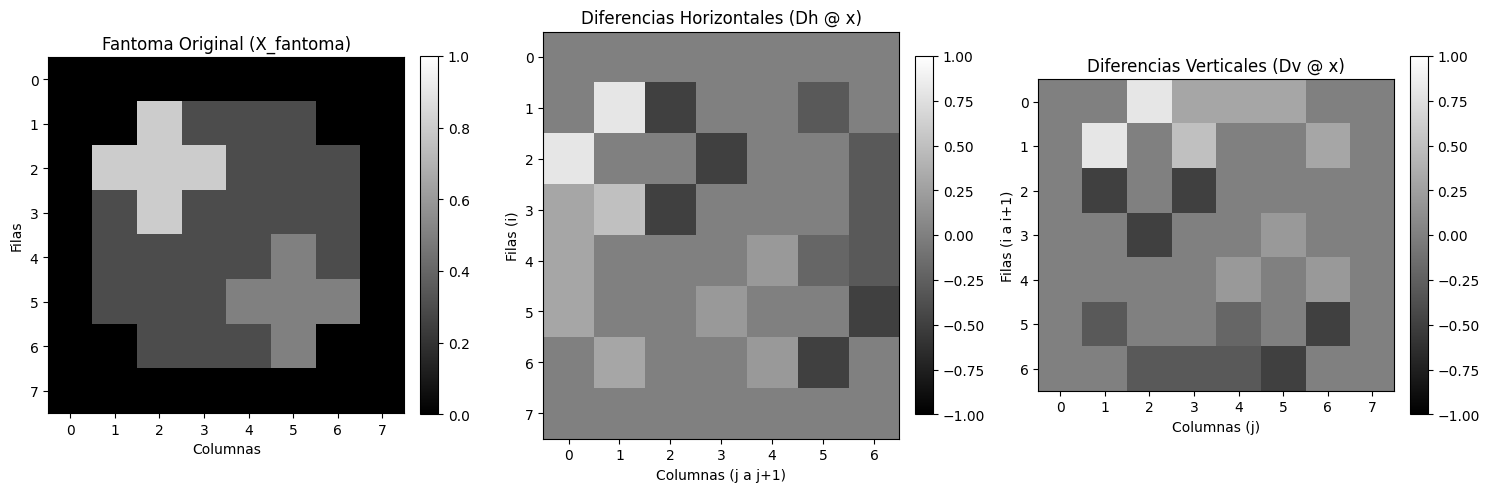

In [ ]:
# Separamos el vector Dx_fantoma en sus componentes horizontal y vertical
mitad = n * (n - 1)
Dx_h = Dx_fantoma[:mitad].reshape(n, n - 1)
Dx_v = Dx_fantoma[mitad:].reshape(n - 1, n)

# Creamos la visualización de tres componentes
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

# Graficamos el Fantoma Original
im_orig = axes[0].imshow(X_fantoma, cmap='gray', vmin=0, vmax=1)
axes[0].set_title('Fantoma Original (X_fantoma)')
axes[0].set_xlabel('Columnas')
axes[0].set_ylabel('Filas')
fig.colorbar(im_orig, ax=axes[0], fraction=0.046, pad=0.04)

# Graficamos las diferencias horizontales
im_h = axes[1].imshow(Dx_h, cmap='gray', vmin=-1, vmax=1)
axes[1].set_title('Diferencias Horizontales (Dh @ x)')
axes[1].set_xlabel('Columnas (j a j+1)')
axes[1].set_ylabel('Filas (i)')
fig.colorbar(im_h, ax=axes[1], fraction=0.046, pad=0.04)

# Graficamos las diferencias verticales
im_v = axes[2].imshow(Dx_v, cmap='gray', vmin=-1, vmax=1)
axes[2].set_title('Diferencias Verticales (Dv @ x)')
axes[2].set_xlabel('Columnas (j)')
axes[2].set_ylabel('Filas (i a i+1)')
fig.colorbar(im_v, ax=axes[2], fraction=0.046, pad=0.04)

plt.tight_layout()
plt.show()

Vemos como las matrices de $D$ forman el "borde" de $x_{fantoma}$.

c) Interpretamos las expresiones provistas de la siguiente manera:
1. $J_{\sigma, \lambda}(\vec{x})$ es la función de costo del problema, cuyo objetivo es aproximar una imágen $\vec{x}$ que sea fiel a los datos pero que, al mismo tiempo, sea "suave" y libre de ruido artificial. Consta de dos términos:
  
   1. $\frac{1}{2} ||A_7x-b_\sigma||^2$ calcula el error cuadrático entre la predicción ($A_7x$)y la medición real ($b_{sigma}$).
   2. Como vimos anteriormente, $Dx$ mide las diferencias de intensidad entre píxeles vecinos. La norma al cuadrado $\|Dx\|^2$ penaliza los cambios bruscos y oscilaciones de alta frecuencia (que usualmente corresponden al ruido). $\lambda$ es un parámetro de regularización que balancea entre la suavidad ($\lambda$ alto) y la ruidosidad ($\lambda$ bajo) de la aproximación. En otras palabras, controla la importancia de la diferencia entre pixeles adyacentes en el costo.

2. La gradiente $\nabla J_{\sigma, \lambda}(x)$ apunta en la dirección de máximo crecimiento de la función de costo. Por ello, para minimizarlo (con, por ejemplo, Gradiente Descendiente), nos movemos en la dirección opuesta.

d) Retomamos las mediciones limpias $\vec{b}_7 = A_7x_{fantoma}$ y el vector aleatorio $\vec{z}$ del ejercicio sobre ruido. Generamos mediciones para $\sigma \in \{0; 0,1; 0,2\}$ mediante el código dado.

In [ ]:
np.random.seed(42)

b_7 = A_7 @ x_fantoma

z = np.random.randn(len(b_7))

escala = np.sqrt(np.mean(b_7**2))

sigma = 0.06
eta = sigma * escala * z
ruidos = eta
b_sigma = b_7 + eta

print(f"Sigma = {sigma:.2f}")
print("Norma del ruido:", np.linalg.norm(ruidos))
print("Primeras 5 mediciones:", b_sigma[:5])

Sigma = 0.06
Norma del ruido: 0.6645884766307322
Primeras 5 mediciones: [0.03267367 1.69090503 3.3426047  2.40018432 1.98459748]


In [ ]:
sigmas = [0, 0.1, 0.2]

b_sigma = []

for sigma in sigmas:
  escala = np.sqrt(np.mean(b_7**2))
  b_sigma.append(b_7 + sigma * escala * z)

e) Adaptamos gradiente descendiente para minimizar $J_{\sigma, \lambda}(\vec{x})$ para cada combinación de $\sigma \in \{0; 0,1; 0,2\}$ y $\lambda \in \{0; 0,1; 0,3; 1\}$, comenzando siempre con $\vec{x}_0 = 0$.

f) Evaluamos distintas tasas de aprendizaje y seleccionamos `lr = 0.01` por ser la que marca un descenso rápido y estable del costo, mientras que tasas mayores como `0.1` provocan la divergencia del algoritmo. Implementamos un criterio de parada basado en la norma del gradiente (sumado al de iteraciones). El criterio de parada no usa el error respecto del fantoma porque, en la práctica, no existe el $x_{fantoma}$ "real" contra el que comparar y medir el error, sino que solamente tenemos las mediciones del escáner. Por lo tanto, no es un buen criterio de optimización.

In [ ]:
def J_costo(x, A, D, b, lam):
    # J(x) = 0.5 * ||Ax - b||^2 + 0.5 * lam * ||Dx||^2
    termino_fidelidad = 0.5 * np.sum((A @ x - b)**2)
    termino_regularizacion = 0.5 * lam * np.sum((D @ x)**2)
    return termino_fidelidad + termino_regularizacion

def gradiente_descendiente_con_historial(A, D, b, lam, x0=None, lr=0.01, iteraciones=100):
    if x0 is None:
        x0 = np.zeros(A.shape[1])

    x = x0.copy()
    historial_costo = []

    for i in range(iteraciones):
        costo = J_costo(x, A, D, b, lam)
        historial_costo.append(costo)

        grad = costo_gradiente(x, A, D, b, lam)
        x = x - lr * grad

    return historial_costo

In [ ]:
def gradiente_descendiente_con_error_relativo(A, D, b, lam, x_real, lr=0.01, iteraciones=300):
    x = np.zeros(A.shape[1])
    historial_error = []
    norma_real = np.linalg.norm(x_real)

    for i in range(iteraciones):
        # Registro del error relativo e_t
        err_rel = np.linalg.norm(x - x_real) / norma_real
        historial_error.append(err_rel)

        # Paso de gradiente
        grad = costo_gradiente(x, A, D, b, lam)
        x = x - lr * grad

    return historial_error

g) Registramos durante las iteraciones el error relativo
$$e_t = \frac{||\vec{x}_t - \vec{x}_{fantoma}||}{||\vec{x}_{fantoma}||}$$

Luego, lo graficamos en función de las iteraciones para los distintos valores de $\lambda$.

<>:14: SyntaxWarning: invalid escape sequence '\l'
<>:16: SyntaxWarning: invalid escape sequence '\s'
<>:14: SyntaxWarning: invalid escape sequence '\l'
<>:16: SyntaxWarning: invalid escape sequence '\s'
/tmp/ipykernel_464/1444087514.py:14: SyntaxWarning: invalid escape sequence '\l'
  ax.plot(errores, label=f'$\lambda$ = {lam}')
/tmp/ipykernel_464/1444087514.py:16: SyntaxWarning: invalid escape sequence '\s'
  ax.set_title(f'Error Relativo $e_t$ con $\sigma$ = {sigma_val}')


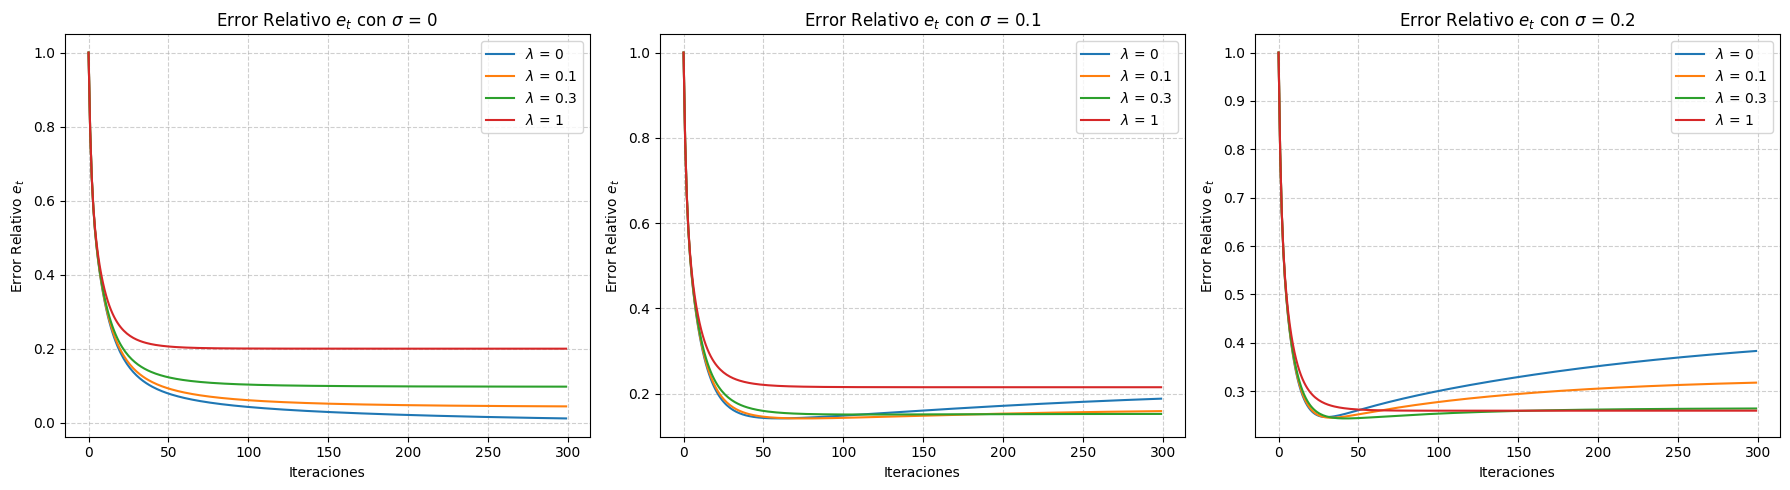

In [ ]:
# Parámetros de simulación
lambdas = [0, 0.1, 0.3, 1]
sigmas = [0, 0.1, 0.2]

# Creamos una figura con subplots para cada nivel de ruido (sigma)
fig, axes = plt.subplots(1, len(sigmas), figsize=(18, 5))

for idx, sigma_val in enumerate(sigmas):
    b_sig = b_sigma[idx]
    ax = axes[idx]

    for lam in lambdas:
        errores = gradiente_descendiente_con_error_relativo(A_7, D, b_sig, lam, x_fantoma, lr=0.01, iteraciones=300)
        ax.plot(errores, label=f'$\lambda$ = {lam}')

    ax.set_title(f'Error Relativo $e_t$ con $\sigma$ = {sigma_val}')
    ax.set_xlabel('Iteraciones')
    ax.set_ylabel('Error Relativo $e_t$')
    ax.grid(True, linestyle='--', alpha=0.6)
    ax.legend()

plt.tight_layout()
plt.show()

lr = 0.1 divergió (valores de costo excesivamente grandes o NaN)


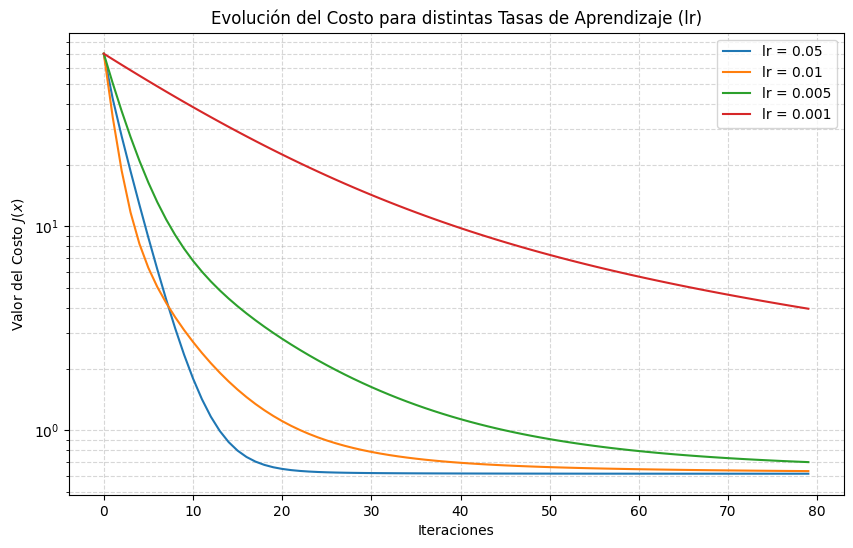

In [ ]:
# Usamos un escenario típico: sigma = 0.1 (b_sigma[1]) y lambda = 0.1
b_prueba = b_sigma[1]
lam_prueba = 0.1
lrs_a_probar = [0.1, 0.05, 0.01, 0.005, 0.001]

plt.figure(figsize=(10, 6))

for lr in lrs_a_probar:
    try:
        historial = gradiente_descendiente_con_historial(A_7, D, b_prueba, lam_prueba, lr=lr, iteraciones=80)
        # Filtramos valores extremadamente altos o NaNs por divergencia para no arruinar la escala del gráfico
        if not np.any(np.isnan(historial)) and np.max(historial) < 1e5:
            plt.plot(historial, label=f'lr = {lr}')
        else:
            print(f"lr = {lr} divergió (valores de costo excesivamente grandes o NaN)")
    except Exception as e:
        print(f"Error con lr = {lr}: {e}")

plt.title('Evolución del Costo para distintas Tasas de Aprendizaje (lr)')
plt.xlabel('Iteraciones')
plt.ylabel('Valor del Costo $J(x)$')
plt.yscale('log') # Escala logarítmica para apreciar mejor las diferencias
plt.grid(True, which="both", linestyle="--", alpha=0.5)
plt.legend()
plt.show()

In [ ]:
def costo_gradiente(x, A, D, b, lam):
    # Calculamos el gradiente analítico
    grad = A.T @ (A @ x - b) + lam * (D.T @ (D @ x))
    return grad

def gradiente_descendiente(A, D, b, lam, x0=None, lr=0.01, iteraciones=500, tol=1e-5):
    if x0 is None:
        x0 = np.zeros(A.shape[1])

    x = x0.copy()
    for i in range(iteraciones):
        grad = costo_gradiente(x, A, D, b, lam)

        # Criterio de parada: Norma del gradiente por debajo del umbral de tolerancia
        if np.linalg.norm(grad) < tol:
            # Opcional: print(f"Convergencia alcanzada en la iteración {i}")
            break

        x = x - lr * grad
    return x

In [ ]:
# Definimos los parametros del problema
lambdas = [0, 0.1, 0.3, 1]

# Diccionarios globales para almacenar los resultados
resultados = {}
errores_relativos = {}
norma_real = np.linalg.norm(x_fantoma)

# Ejecutamos las reconstrucciones y calculamos el error relativo
for i, sigma_val in enumerate(sigmas):
    b_sig = b_sigma[i] # Tomamos la medicion correspondiente
    errores_relativos[sigma_val] = {}
    for lam in lambdas:
        x_rec = gradiente_descendiente(A_7, D, b_sig, lam, lr=0.01, iteraciones=500)
        resultados[(sigma_val, lam)] = x_rec

        # Almacenamos el error relativo final globalmente de forma inmediata
        errores_relativos[sigma_val][lam] = np.linalg.norm(x_rec - x_fantoma) / norma_real

h) Organizamos las reconstrucciones finales en una grilla cada fila representa un valor de $\sigma$ y cada columna, el de $\lambda$. A su vez, indicamos el error relativo $e_t$ sobre cada reconstrucción$

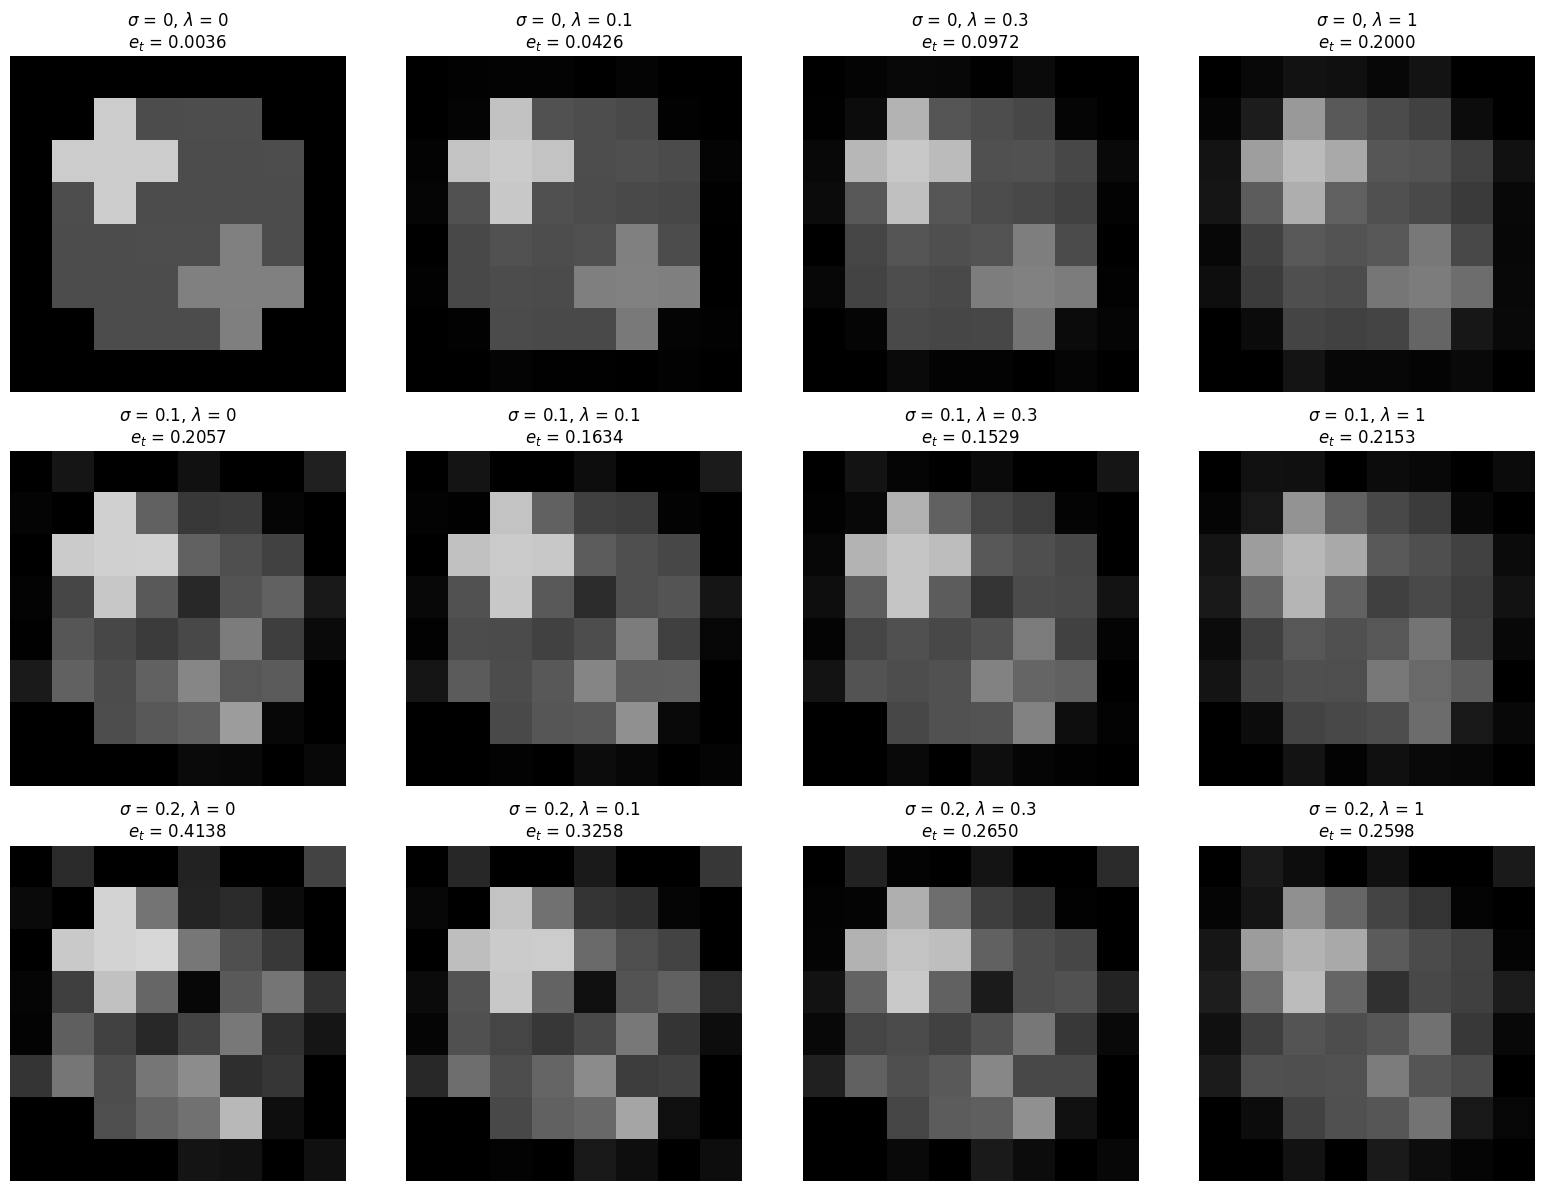

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Visualizamos los resultados leyendo directamente del diccionario global
fig, axes = plt.subplots(len(sigmas), len(lambdas), figsize=(16, 12))

for i, sigma_val in enumerate(sigmas):
    for j, lam in enumerate(lambdas):
        x_rec = resultados[(sigma_val, lam)]
        X_rec = x_rec.reshape(8, 8)

        # Lectura directa del error relativo global simplificado
        err_rel_final = errores_relativos[sigma_val][lam]

        ax = axes[i, j]
        im = ax.imshow(X_rec, cmap='gray', vmin=0, vmax=1)

        # Usamos raw-strings (r) para evitar advertencias de LaTeX
        titulo = r"$\sigma$ = " + str(sigma_val) + r", $\lambda$ = " + str(lam) + "\n" + r"$e_t$ = " + f"{err_rel_final:.4f}"
        ax.set_title(titulo)
        ax.axis('off')

plt.tight_layout()
plt.show()

i) Resumimos los errores relativos y las normas de los residuos en un mapa de calor cuyos ejes son $\sigma$ y $\lambda$. Para cada nivel de ruido, identificamos qué valor de $\lambda$ produjo el menor error.

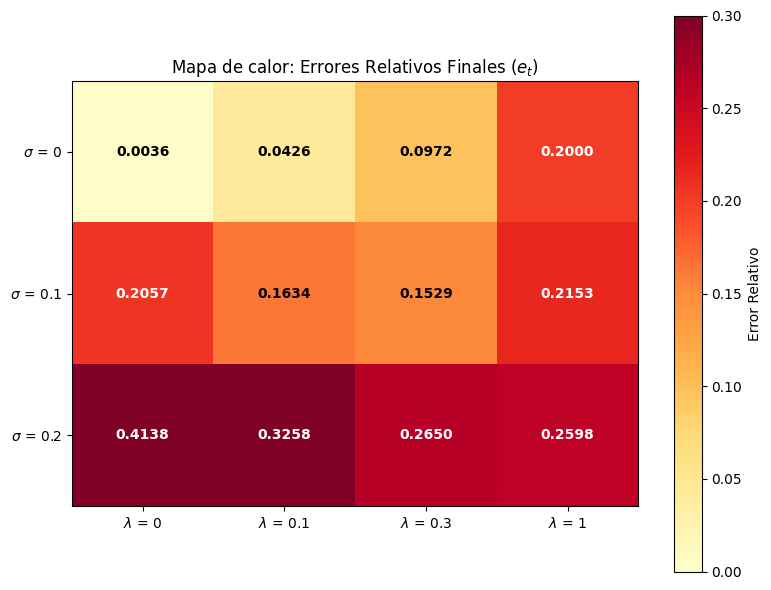

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Creamos la matriz numérica leyendo de la variable global existente errores_relativos
matriz_calor = np.zeros((len(sigmas), len(lambdas)))
for i, sigma_val in enumerate(sigmas):
    for j, lam in enumerate(lambdas):
        matriz_calor[i, j] = errores_relativos[sigma_val][lam]

# 2. Graficamos el mapa de calor
fig, ax = plt.subplots(figsize=(8, 6))
im = ax.imshow(matriz_calor, cmap="YlOrRd", vmin=0, vmax=0.3)

# Configuramos los ejes
ax.set_xticks(range(len(lambdas)), labels=[f"$\\lambda$ = {lam}" for lam in lambdas])
ax.set_yticks(range(len(sigmas)), labels=[fr"$\sigma$ = {sig_val}" for sig_val in sigmas])

# Agregamos las anotaciones de texto leyendo directamente de la matriz
for i in range(len(sigmas)):
    for j in range(len(lambdas)):
        text = ax.text(j, i, f"{matriz_calor[i, j]:.4f}",
                       ha="center", va="center",
                       color="black" if matriz_calor[i, j] < 0.18 else "white",
                       fontweight="bold")

ax.set_title("Mapa de calor: Errores Relativos Finales ($e_t$)")
fig.colorbar(im, ax=ax, label="Error Relativo")
fig.tight_layout()
plt.show()

j) En el caso de sigmas bajos, la reconstrucción fue casi perfecta para lambda igual a cero. Aún así, al aumentar el ruido ($\sigma$), se producen los mayores errores. La regularización excesiva ($\lambda$ altos) justamente regulariza el error; estandariza a un valor medio.